[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bihjane/data-science-and-ai-k-12-teaching-tools/blob/main/intelligent-futures-free-courses/colab-notebooks/04_classification_iris_full_pipeline.ipynb)

# A complete classification model, start to finish
**Level:** intermediate · **Time:** 60 minutes · **Models:** logistic regression, decision tree, k-nearest neighbours

**Question:** Can a model tell three species of iris flower apart from four measurements of their petals and sepals?

Data: the classic Iris dataset (150 flowers), built into scikit-learn.

You will follow the full workflow used by data scientists: define, load, explore, split, scale, train, evaluate, tune, explain, save and use.

## How to use this notebook
1. Click **Open in Colab** above, or upload this file at [colab.research.google.com](https://colab.research.google.com) (File > Upload notebook).
2. Run each code cell in order with **Shift + Enter**.
3. Before running a cell, **predict** what it will show. After running it, check your prediction.
4. Try the **Your turn** tasks at the end of each step.

No installs or downloads are needed. Everything runs free in your browser.

## Step 1. Load and look

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
df = iris.frame
df["species"] = df.target.map(dict(enumerate(iris.target_names)))
print(df.shape)
df.sample(5, random_state=1)

(150, 6)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
14,5.8,4.0,1.2,0.2,0,setosa
98,5.1,2.5,3.0,1.1,1,versicolor
75,6.6,3.0,4.4,1.4,1,versicolor
16,5.4,3.9,1.3,0.4,0,setosa
131,7.9,3.8,6.4,2.0,2,virginica


In [2]:
df.species.value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

The classes are **balanced** (50 each), so accuracy is a fair first measure.

## Step 2. Explore

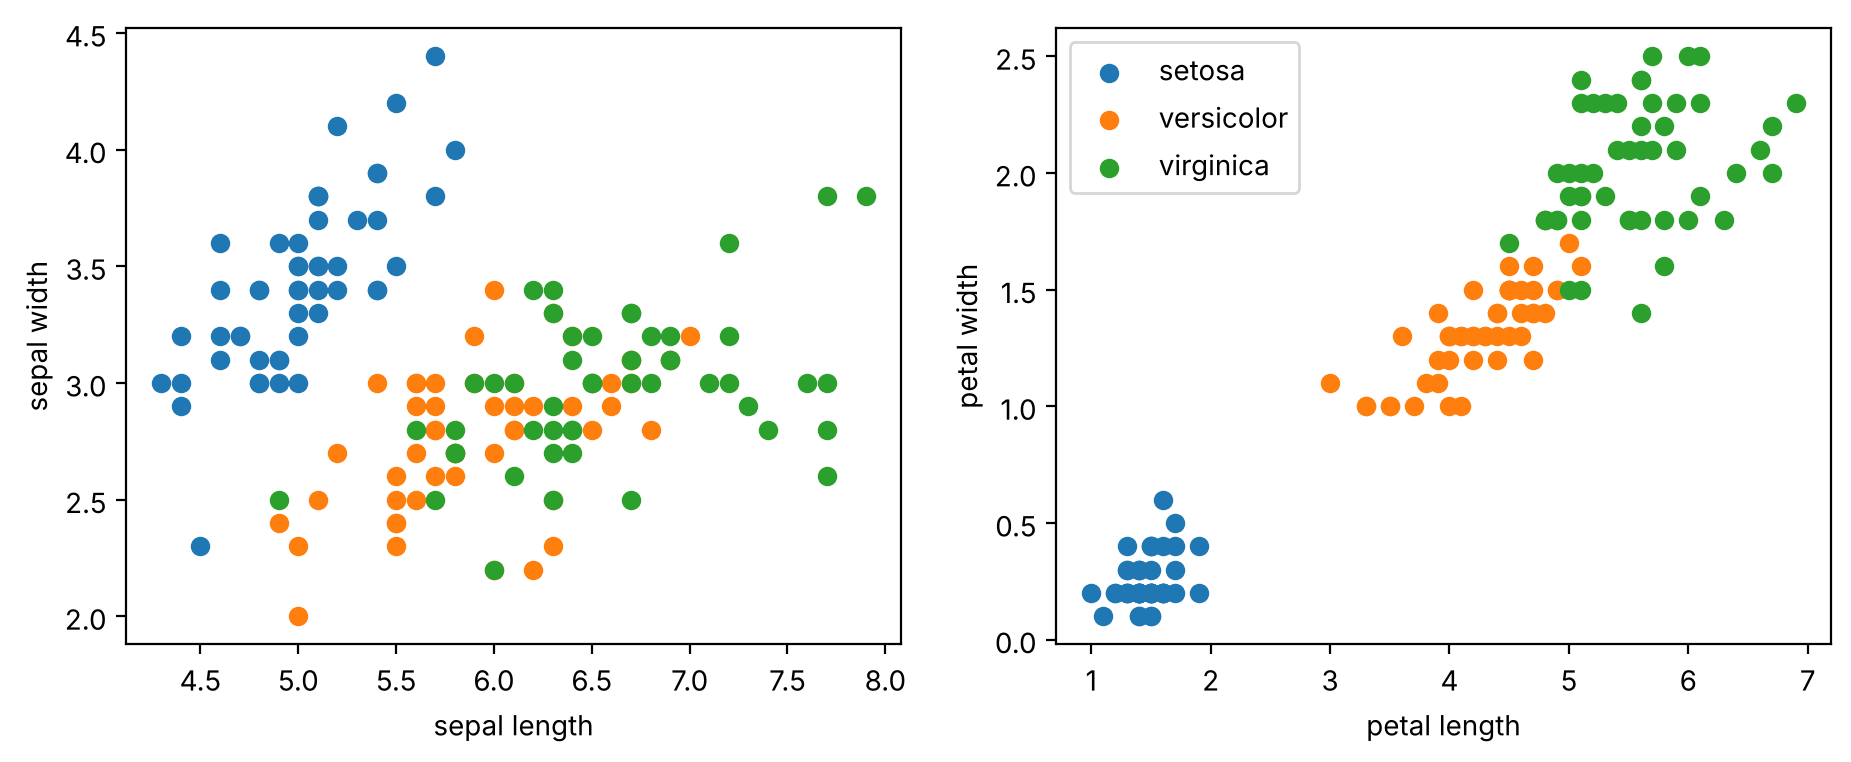

In [3]:
colors = {"setosa": "tab:blue", "versicolor": "tab:orange", "virginica": "tab:green"}
fig, ax = plt.subplots(1, 2, figsize=(11,4))
for s, g in df.groupby("species"):
    ax[0].scatter(g["sepal length (cm)"], g["sepal width (cm)"], label=s, c=colors[s])
    ax[1].scatter(g["petal length (cm)"], g["petal width (cm)"], label=s, c=colors[s])
ax[0].set_xlabel("sepal length"); ax[0].set_ylabel("sepal width")
ax[1].set_xlabel("petal length"); ax[1].set_ylabel("petal width")
ax[1].legend(); plt.show()

**Your turn:** Which pair of measurements separates the species better? Why might that matter for the model?

## Step 3. Split into training and test sets

In [4]:
from sklearn.model_selection import train_test_split

X = df[iris.feature_names]
y = df["species"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print(len(X_train), "training flowers,", len(X_test), "test flowers")

112 training flowers, 38 test flowers


## Step 4. Build pipelines and train three models
A **pipeline** bundles preparation (scaling) and the model, so the same steps run on new data.

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision tree":       DecisionTreeClassifier(max_depth=3, random_state=42),
    "k-nearest neighbours": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
}
for name, m in models.items():
    m.fit(X_train, y_train)
    print(f"{name:22s} test accuracy: {accuracy_score(y_test, m.predict(X_test)):.2f}")

Logistic regression    test accuracy: 0.92
Decision tree          test accuracy: 0.89
k-nearest neighbours   test accuracy: 0.92


## Step 5. Evaluate in detail
A **confusion matrix** shows which species get mixed up.

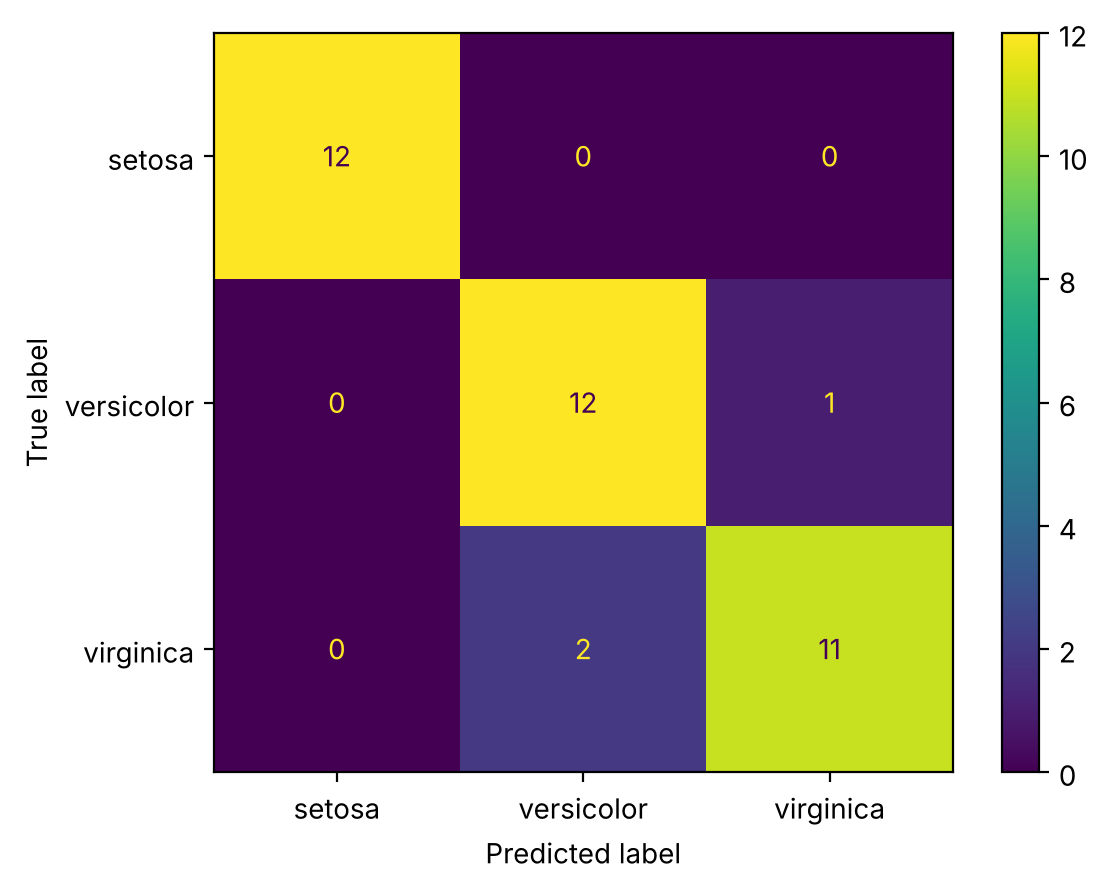

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.86      0.92      0.89        13
   virginica       0.92      0.85      0.88        13

    accuracy                           0.92        38
   macro avg       0.92      0.92      0.92        38
weighted avg       0.92      0.92      0.92        38



In [6]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

best = models["Logistic regression"]
ConfusionMatrixDisplay.from_estimator(best, X_test, y_test)
plt.show()
print(classification_report(y_test, best.predict(X_test)))

## Step 6. Check stability with cross-validation
One split can be lucky. Cross-validation tests on 5 different splits.

In [7]:
from sklearn.model_selection import cross_val_score

for name, m in models.items():
    scores = cross_val_score(m, X, y, cv=5)
    print(f"{name:22s} mean {scores.mean():.2f}  (each split: {np.round(scores, 2)})")

Logistic regression    mean 0.96  (each split: [0.97 1.   0.93 0.9  1.  ])
Decision tree          mean 0.97  (each split: [0.97 0.97 0.93 1.   1.  ])


k-nearest neighbours   mean 0.96  (each split: [0.97 0.97 0.93 0.93 1.  ])


## Step 7. Tune a setting
How many neighbours should k-NN use? Try several and compare.

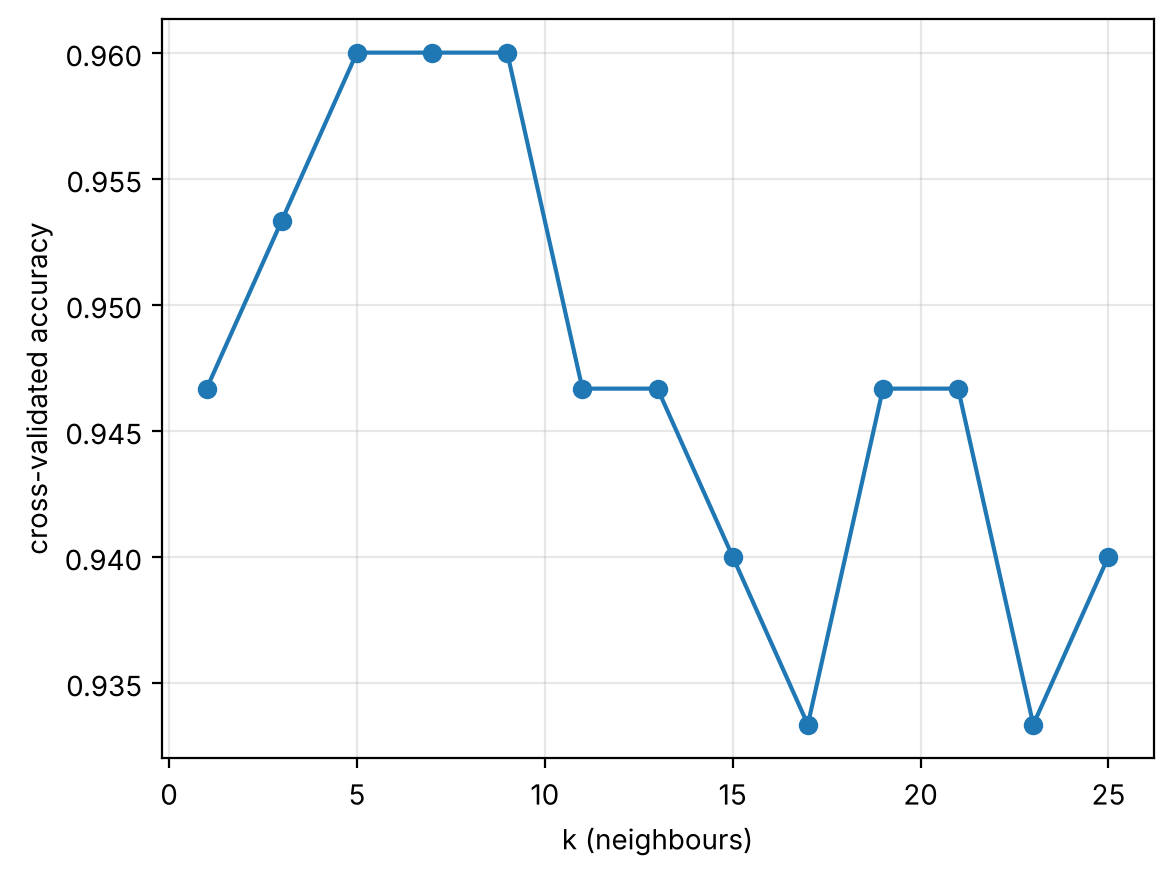

Best k: 5


In [8]:
ks = range(1, 26, 2)
cv_means = [cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)), X, y, cv=5).mean() for k in ks]
plt.plot(list(ks), cv_means, "o-"); plt.xlabel("k (neighbours)"); plt.ylabel("cross-validated accuracy"); plt.grid(alpha=0.3); plt.show()
print("Best k:", list(ks)[int(np.argmax(cv_means))])

## Step 8. Explain the model
A decision tree can be read like a flowchart.

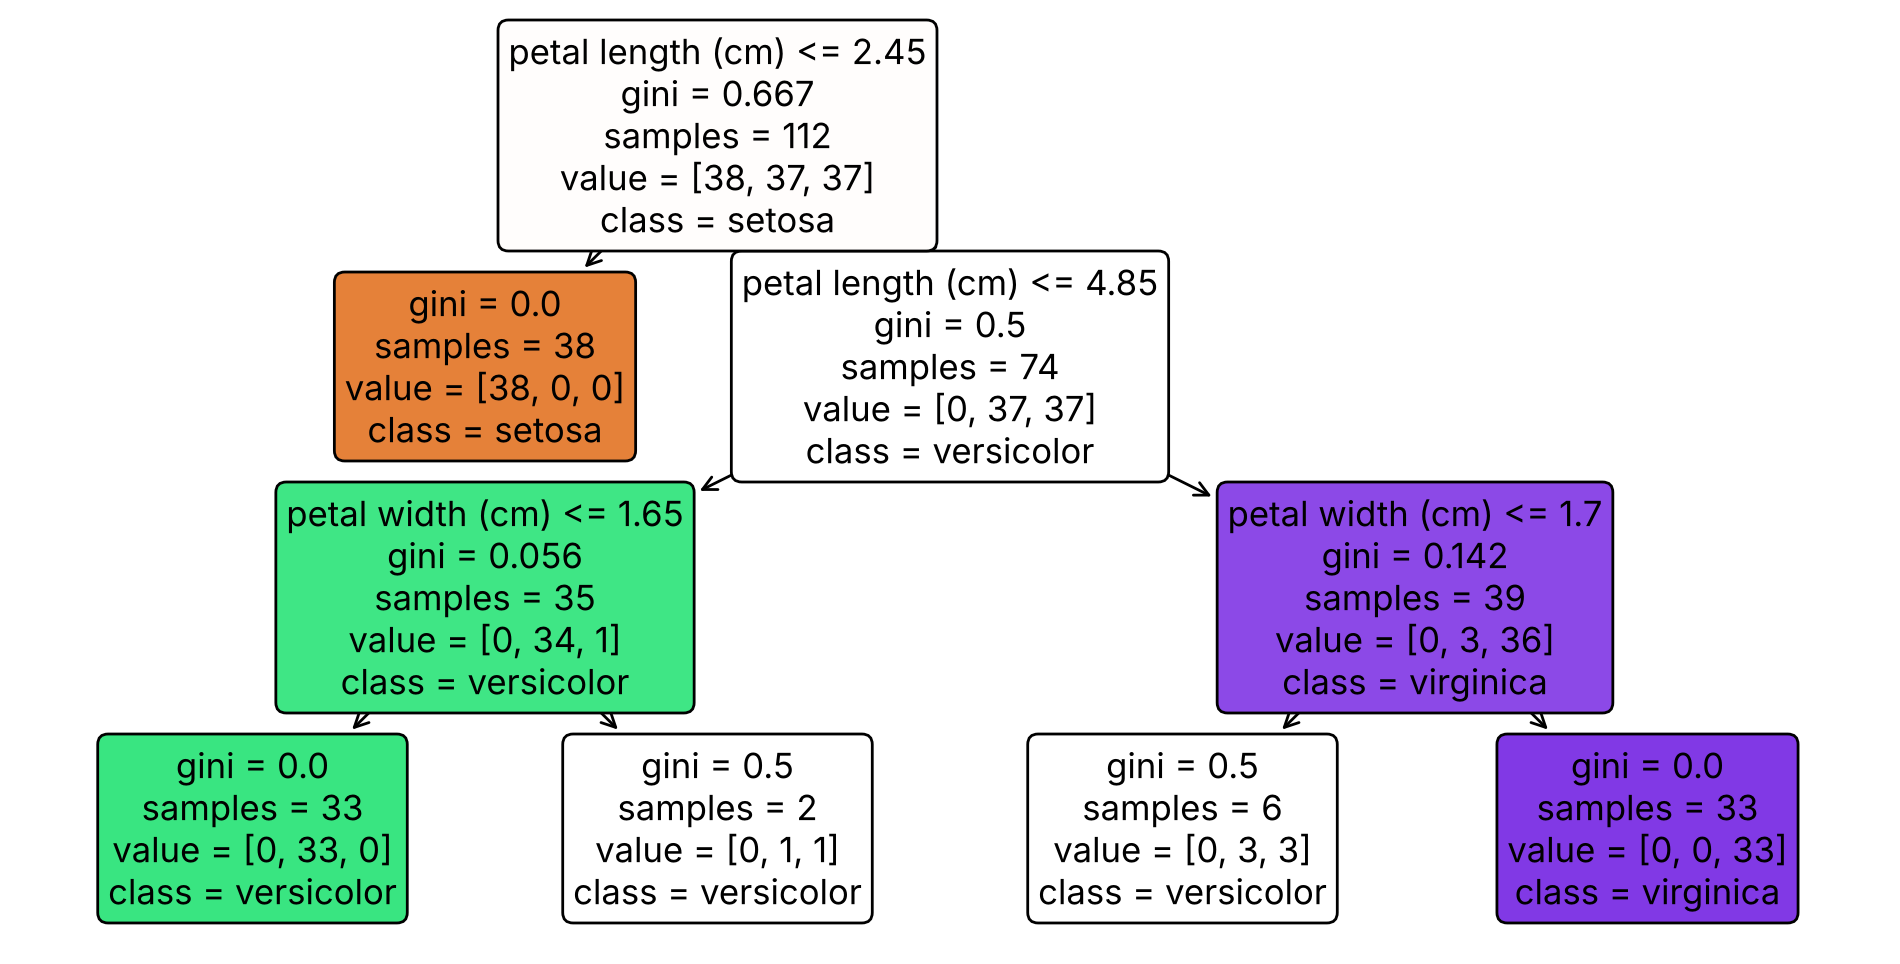

In [9]:
from sklearn.tree import plot_tree
tree = models["Decision tree"]
plt.figure(figsize=(12,6))
plot_tree(tree, feature_names=iris.feature_names, class_names=tree.classes_, filled=True, rounded=True)
plt.show()

## Step 9. Save the model and use it on a new flower

In [10]:
import joblib
joblib.dump(best, "iris_model.joblib")            # saved file appears in the Colab Files panel

loaded = joblib.load("iris_model.joblib")
new_flower = pd.DataFrame([[5.9, 3.0, 5.1, 1.8]], columns=iris.feature_names)
print("Prediction:", loaded.predict(new_flower)[0])
probs = loaded.predict_proba(new_flower)[0]
for species, p in zip(loaded.classes_, probs):
    print(f"  {species}: {p:.0%}")

Prediction: virginica
  setosa: 1%
  versicolor: 32%
  virginica: 68%


## Your turn: extensions
1. Train using only the two sepal measurements. How much accuracy is lost?
2. Use the same steps on `load_wine()` (178 wines, 13 chemical measurements).
3. Write a model card: what the model does, its accuracy, and when it should not be used.

---
*Intelligent Futures · Dr. Janet Bih Shufor · Free for classroom use with attribution.*